<a href="https://colab.research.google.com/github/Kwakjaemin1007/Like-lion_-Smart-farm/blob/main/smartfarm_strawberry_KTD_YOLOv8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. uv 설치 (아주 가벼워서 순식간에 설치됨)
!pip install uv

# 2. uv를 사용하여 ultralytics 설치
# (system python 환경에 설치하라는 옵션을 줘야 코랩에서 바로 인식합니다)
!uv pip install ultralytics --system -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 50.6 MB/s eta 0:00:00


In [ ]:
import os
import sys
from ultralytics import YOLO

# 1. ultralytics 패키지 설치 경로 찾기
import ultralytics
package_dir = os.path.dirname(ultralytics.__file__)
conv_file = os.path.join(package_dir, 'nn', 'modules', 'conv.py')
tasks_file = os.path.join(package_dir, 'nn', 'tasks.py')

print(f"🔧 라이브러리 경로 확인됨: {package_dir}")

# 2. Triplet Attention 소스 코드 정의 (논문 구현체)
triplet_attention_code = """

# --- [KTD-YOLOv8 Patch] Triplet Attention Module ---
class TripletAttention(nn.Module):
    def __init__(self, no_spatial=False):
        super(TripletAttention, self).__init__()
        self.cw = BasicConv(2, 1, 7, relu=False)
        self.hc = BasicConv(2, 1, 7, relu=False)
        self.no_spatial = no_spatial
        if not no_spatial:
            self.hw = BasicConv(2, 1, 7, relu=False)

    def forward(self, x):
        x_perm1 = x.permute(0, 2, 1, 3).contiguous()
        x_out1 = self.cw(torch.cat((torch.max(x_perm1, 1)[0].unsqueeze(1), torch.mean(x_perm1, 1).unsqueeze(1)), dim=1))
        x_out1 = x_out1.sigmoid()
        x_out1 = x_out1.permute(0, 2, 1, 3).contiguous()

        x_perm2 = x.permute(0, 3, 2, 1).contiguous()
        x_out2 = self.hc(torch.cat((torch.max(x_perm2, 1)[0].unsqueeze(1), torch.mean(x_perm2, 1).unsqueeze(1)), dim=1))
        x_out2 = x_out2.sigmoid()
        x_out2 = x_out2.permute(0, 3, 2, 1).contiguous()

        if not self.no_spatial:
            x_out = self.hw(torch.cat((torch.max(x, 1)[0].unsqueeze(1), torch.mean(x, 1).unsqueeze(1)), dim=1))
            x_out = x_out.sigmoid()
            return 1/3 * (x * x_out + x * x_out1 + x * x_out2)
        else:
            return 1/2 * (x * x_out1 + x * x_out2)
# ---------------------------------------------------
"""

# 3. conv.py 파일에 TripletAttention 클래스 추가
with open(conv_file, 'r') as f:
    content = f.read()

if "class TripletAttention" not in content:
    with open(conv_file, 'a') as f:
        f.write(triplet_attention_code)
    print(f"✅ [conv.py] Triplet Attention 코드 주입 완료.")
else:
    print(f"ℹ️ [conv.py] 이미 코드가 존재합니다.")

# 4. tasks.py 파일 수정 (모델이 yaml에서 TripletAttention을 읽을 수 있게 등록)
with open(tasks_file, 'r') as f:
    tasks_content = f.read()

# 이미 등록되었는지 확인 후 수정
if "'TripletAttention': TripletAttention" not in tasks_content:
    # 모듈 임포트 부분 수정 (conv 모듈에서 가져오기)
    if "from ultralytics.nn.modules.conv import (" in tasks_content:
        tasks_content = tasks_content.replace(
            "from ultralytics.nn.modules.conv import (",
            "from ultralytics.nn.modules.conv import (TripletAttention, "
        )

    # parse_model 함수 내부 매핑에 추가
    # 보통 'if m in (Classify, Conv, ...)' 형태의 구문을 찾아서 추가해야 함.
    # 안전하게 파일 끝의 매핑 로직이나 locals() 활용 부분 근처는 건드리기 어려우므로,
    # eval()을 사용하는 Ultralytics 특성상 import만 잘 되어 있으면 됩니다.

    with open(tasks_file, 'w') as f:
        f.write(tasks_content)
    print(f"✅ [tasks.py] Import 구문 수정 완료. (이제 yaml에서 사용 가능)")
else:
    print(f"ℹ️ [tasks.py] 이미 수정되었습니다.")

print("\n🚀 YOLOv8 라이브러리 개조가 완료되었습니다! 이제 KTD 모델을 정의할 수 있습니다.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🔧 라이브러리 경로 확인됨: /usr/local/lib/python3.12/dist-packages/ultralytics
✅ [conv.py] Triplet Attention 코드 주입 완료.
✅ [tasks.py] Import 구문 수정 완료. (이제 yaml에서 사용 가능)

🚀 YOLOv8 라이브러리 개조가 완료되었습니다! 이제 KTD 모델을 정의할 수 있습니다.


In [ ]:
import yaml

# KTD-YOLOv8 구조 정의 (Based on YOLOv8s)
# Backbone 끝과 Neck 부분에 TripletAttention을 추가하여 병해의 미세 특징을 잡습니다.
ktd_yaml_content = """
# Ultralytics YOLO 🚀, AGPL-3.0 license
# KTD-YOLOv8 (Triplet Attention Version) for Strawberry Disease Detection

nc: 20  # AI Hub 데이터셋 (20개 클래스)
scales: # model compound scaling constants, i.e. 'model=yolov8n.yaml' will call yolov8.yaml with scale 'n'
  # [depth, width, max_channels]
  s: [0.33, 0.50, 1024]

backbone:
  # [from, repeats, module, args]
  - [-1, 1, Conv, [64, 3, 2]]  # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]] # 1-P2/4
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]] # 3-P3/8
  - [-1, 6, C2f, [256, True]]

  # [KTD 핵심] Triplet Attention 추가 (작은 병해 특징 강조)
  - [-1, 1, TripletAttention, []] # 5

  - [-1, 1, Conv, [512, 3, 2]] # 6-P4/16
  - [-1, 6, C2f, [512, True]]

  # [KTD 핵심] Triplet Attention 추가
  - [-1, 1, TripletAttention, []] # 8

  - [-1, 1, Conv, [1024, 3, 2]] # 9-P5/32
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]  # 11

head:
  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]
  - [[-1, 8], 1, Concat, [1]] # cat backbone P4 (Attention 적용된 8번 레이어와 결합)
  - [-1, 3, C2f, [512]] # 14

  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]
  - [[-1, 5], 1, Concat, [1]] # cat backbone P3 (Attention 적용된 5번 레이어와 결합)
  - [-1, 3, C2f, [256]] # 17 (P3/8-small)

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 14], 1, Concat, [1]] # cat head P4
  - [-1, 3, C2f, [512]] # 20 (P4/16-medium)

  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 11], 1, Concat, [1]] # cat head P5
  - [-1, 3, C2f, [1024]] # 23 (P5/32-large)

  - [[17, 20, 23], 1, Detect, [nc]] # Detect(P3, P4, P5)
"""

# yaml 파일 저장
ktd_yaml_path = '/content/ktd_yolov8_strawberry.yaml'
with open(ktd_yaml_path, 'w') as f:
    f.write(ktd_yaml_content)

print(f"✅ KTD-YOLOv8 설계도 생성 완료: {ktd_yaml_path}")

✅ KTD-YOLOv8 설계도 생성 완료: /content/ktd_yolov8_strawberry.yaml


In [ ]:
# 1. 시각화 라이브러리 설치
!pip install torchinfo

from torchinfo import summary
from ultralytics import YOLO

# 2. 모델 로드 (이미 메모리에 model 변수가 있다면 생략 가능)
# 주의: TripletAttention 클래스 정의 코드가 먼저 실행되어 있어야 합니다.
ktd_yaml_path = '/content/ktd_yolov8_strawberry.yaml'
model = YOLO(ktd_yaml_path)  # 구조만 불러오기 (학습된 가중치 로드해도 됨)

# 3. 아키텍처 요약 출력
# 입력 크기: (배치사이즈 1, 채널 3, 높이 640, 너비 640)
print("\n📊 KTD-YOLOv8 Architecture Summary:")
summary(model.model, input_size=(1, 3, 640, 640), col_names=["input_size", "output_size", "num_params", "kernel_size", "mult_adds"])

WARNING ⚠️ no model scale passed. Assuming scale='s'.


KeyError: 'TripletAttention'

In [ ]:
import torch
import torch.nn as nn
import ultralytics.nn.tasks as tasks
from ultralytics import YOLO
from torchinfo import summary # 시각화 도구

# ==============================================================================
# 1. 커스텀 모듈 정의 (아키텍처를 조립하기 위한 부품)
# ==============================================================================
# 이 부분이 없으면 YAML 파일을 읽을 때 "TripletAttention이 뭐야?" 하고 에러가 납니다.
class BasicConv(nn.Module):
    def __init__(self, in_planes, out_planes, kernel_size, stride=1, padding=0, dilation=1, groups=1, relu=True, bn=True, bias=False):
        super(BasicConv, self).__init__()
        self.out_channels = out_planes
        self.conv = nn.Conv2d(in_planes, out_planes, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups, bias=bias)
        self.bn = nn.BatchNorm2d(out_planes, eps=1e-5, momentum=0.01, affine=True) if bn else None
        self.relu = nn.ReLU() if relu else None

    def forward(self, x):
        x = self.conv(x)
        if self.bn is not None:
            x = self.bn(x)
        if self.relu is not None:
            x = self.relu(x)
        return x

class TripletAttention(nn.Module):
    def __init__(self, no_spatial=False):
        super(TripletAttention, self).__init__()
        self.cw = BasicConv(2, 1, 7, padding=3, relu=False)
        self.hc = BasicConv(2, 1, 7, padding=3, relu=False)
        self.no_spatial = no_spatial
        if not no_spatial:
            self.hw = BasicConv(2, 1, 7, padding=3, relu=False)

    def forward(self, x):
        x_perm1 = x.permute(0, 2, 1, 3).contiguous()
        x_out1 = self.cw(torch.cat((torch.max(x_perm1, 1)[0].unsqueeze(1), torch.mean(x_perm1, 1).unsqueeze(1)), dim=1))
        x_out1 = x_out1.sigmoid()
        x_out1 = x_out1.permute(0, 2, 1, 3).contiguous()

        x_perm2 = x.permute(0, 3, 2, 1).contiguous()
        x_out2 = self.hc(torch.cat((torch.max(x_perm2, 1)[0].unsqueeze(1), torch.mean(x_perm2, 1).unsqueeze(1)), dim=1))
        x_out2 = x_out2.sigmoid()
        x_out2 = x_out2.permute(0, 3, 2, 1).contiguous()

        if not self.no_spatial:
            x_out = self.hw(torch.cat((torch.max(x, 1)[0].unsqueeze(1), torch.mean(x, 1).unsqueeze(1)), dim=1))
            x_out = x_out.sigmoid()
            return 1/3 * (x * x_out + x * x_out1 + x * x_out2)
        else:
            return 1/2 * (x * x_out1 + x * x_out2)

# ==============================================================================
# 2. 강제 주입 (Monkey Patching)
# ==============================================================================
# 학습을 안 하더라도 모델을 '빌드'하려면 이 과정이 필수입니다.
if 'TripletAttention' not in tasks.__dict__:
    tasks.__dict__['TripletAttention'] = TripletAttention

# ==============================================================================
# 3. KTD-YOLOv8 YAML 파일 생성 (설계도)
# ==============================================================================
import yaml
ktd_yaml_content = """
# KTD-YOLOv8 Architecture (Visualization Only)
nc: 20
scales:
  s: [0.33, 0.50, 1024]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, TripletAttention, []] # <--- 커스텀 모듈
  - [-1, 1, Conv, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, TripletAttention, []] # <--- 커스텀 모듈
  - [-1, 1, Conv, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]

head:
  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]
  - [[-1, 8], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]
  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]
  - [[-1, 5], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 14], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 11], 1, Concat, [1]]
  - [-1, 3, C2f, [1024]]
  - [[17, 20, 23], 1, Detect, [nc]]
"""
with open('ktd_vis.yaml', 'w') as f:
    f.write(ktd_yaml_content)

# ==============================================================================
# 4. 모델 빌드 및 아키텍처 시각화 (학습 X)
# ==============================================================================
print("🏗️ 모델을 조립 중입니다...")
model = YOLO('ktd_vis.yaml') # 여기서 모델이 메모리에 생성됩니다.

print("\n" + "="*50)
print("📊 KTD-YOLOv8 아키텍처 상세 구조")
print("="*50)

# 방법 1: 간단히 구조 출력
print(model.model)

print("\n" + "="*50)
print("📊 Layer별 파라미터 및 입출력 크기 (torchinfo)")
print("="*50)

# 방법 2: 상세 정보 출력 (Input size: (1, 3, 640, 640) 기준)
summary(model.model, input_size=(1, 3, 640, 640),
        col_names=["input_size", "output_size", "num_params", "kernel_size"],
        depth=3) # depth를 조절하면 더 깊은 내부까지 보입니다.

🏗️ 모델을 조립 중입니다...
WARNING ⚠️ no model scale passed. Assuming scale='s'.

📊 KTD-YOLOv8 아키텍처 상세 구조
DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, mom

Layer (type:depth-idx)                             Input Shape               Output Shape              Param #                   Kernel Shape
DetectionModel                                     [1, 3, 640, 640]          [1, 24, 8400]             --                        --
├─Sequential: 1-1                                  --                        --                        --                        --
│    └─Conv: 2-1                                   [1, 3, 640, 640]          [1, 32, 320, 320]         --                        --
│    │    └─Conv2d: 3-1                            [1, 3, 640, 640]          [1, 32, 320, 320]         864                       [3, 3]
│    │    └─BatchNorm2d: 3-2                       [1, 32, 320, 320]         [1, 32, 320, 320]         64                        --
│    └─Detect: 2-98                                --                        --                        (recursive)               --
│    │    └─ModuleList: 3-124                      --         

In [ ]:
import os
import glob
import shutil
from sklearn.model_selection import train_test_split

# ==============================================================================
# 1. 실제 데이터가 숨어있는 진짜 경로 찾기 (Debugging)
# ==============================================================================
base_search_dir = '/content/drive/MyDrive/strawberry_data_640x640.zip' # 여기서부터 샅샅이 뒤집니다

print("🔍 데이터 파일 위치를 추적 중입니다...")

# jpg, png 이미지가 있는 모든 경로 수집
all_jpgs = glob.glob(os.path.join(base_search_dir, '**', '*.jpg'), recursive=True) + \
           glob.glob(os.path.join(base_search_dir, '**', '*.png'), recursive=True)

if len(all_jpgs) == 0:
    print("❌ 오류: 압축 해제된 폴더 안에 이미지 파일이 하나도 없습니다!")
    print("   -> 해결책: 압축 해제 코드를 다시 실행하거나, zip 파일 경로를 확인하세요.")
else:
    print(f"✅ 총 {len(all_jpgs)}개의 이미지 파일을 발견했습니다!")
    print(f"   - 예시 경로: {all_jpgs[0]}")

    # 이미지가 발견된 폴더의 상위 경로를 새로운 root로 잡습니다.
    # 예: /content/datasets/strawberry/images/train/a.jpg -> /content/datasets/strawberry
    # 보통 images 폴더가 있는 곳의 상위 폴더가 데이터셋 루트입니다.

    sample_path = os.path.dirname(all_jpgs[0]) # 이미지가 있는 폴더
    # 상위로 올라가며 'images'나 'labels' 폴더가 있는지 확인
    new_dataset_root = base_search_dir

    # 경로 자동 보정 로직
    if 'images' in sample_path:
        new_dataset_root = sample_path.split('images')[0]
    else:
        # images 폴더 안에 없고 그냥 흩뿌려져 있는 경우, 해당 폴더를 루트로
        new_dataset_root = sample_path

    print(f"🎯 수정된 데이터셋 루트 경로: {new_dataset_root}")

    # ==============================================================================
    # 2. 짝 맞추기 재시도 (파일명 대조)
    # ==============================================================================
    print("\n🔄 이미지-라벨 짝 맞추기를 재시도합니다...")

    valid_pairs = []
    # 모든 txt 파일 미리 찾기 (속도 최적화)
    all_txts = glob.glob(os.path.join(new_dataset_root, '**', '*.txt'), recursive=True)
    # 검색 편의를 위해 {파일명: 전체경로} 딕셔너리 생성
    txt_map = {os.path.splitext(os.path.basename(p))[0]: p for p in all_txts}

    for img_path in all_jpgs:
        base_name = os.path.splitext(os.path.basename(img_path))[0]

        # 딕셔너리에서 같은 이름의 txt 찾기
        if base_name in txt_map:
            valid_pairs.append((img_path, txt_map[base_name]))

    print(f"✅ 매칭 결과: {len(all_jpgs)}개 이미지 중 {len(valid_pairs)}개의 라벨 쌍을 찾았습니다.")

    if len(valid_pairs) == 0:
        print("❌ 여전히 짝을 찾지 못했습니다. 파일명을 확인해보세요.")
        print(f"   - 이미지 예시: {os.path.basename(all_jpgs[0])}")
        if len(all_txts) > 0:
            print(f"   - 라벨 예시: {os.path.basename(all_txts[0])}")
        else:
            print("   - 라벨 파일(.txt)이 하나도 없습니다.")
    else:
        # ==============================================================================
        # 3. (성공 시) 데이터 분할 및 이동 실행
        # ==============================================================================
        print("\n🚀 데이터 분할 및 폴더 정리를 시작합니다 (8:1:1)...")

        # 분할
        train_pairs, test_val_pairs = train_test_split(valid_pairs, test_size=0.2, random_state=42, shuffle=True)
        val_pairs, test_pairs = train_test_split(test_val_pairs, test_size=0.5, random_state=42, shuffle=True)

        # 타겟 폴더 준비 (수정된 루트 기준)
        target_root = new_dataset_root.rstrip('/') # 끝에 / 제거
        images_dir = os.path.join(target_root, 'images')
        labels_dir = os.path.join(target_root, 'labels')

        def move_files_safe(pairs, split_name):
            t_img_dir = os.path.join(images_dir, split_name)
            t_lbl_dir = os.path.join(labels_dir, split_name)
            os.makedirs(t_img_dir, exist_ok=True)
            os.makedirs(t_lbl_dir, exist_ok=True)

            for img_src, lbl_src in pairs:
                # 파일명 중복 방지를 위해 원본 경로 구조 일부 반영하거나 그냥 덮어쓰기
                # 여기서는 파일명만 사용
                shutil.move(img_src, os.path.join(t_img_dir, os.path.basename(img_src)))
                shutil.move(lbl_src, os.path.join(t_lbl_dir, os.path.basename(lbl_src)))

        # 이동 실행
        move_files_safe(train_pairs, 'train')
        move_files_safe(val_pairs, 'val')
        move_files_safe(test_pairs, 'test')

        print(f"🎉 완료! 데이터셋이 '{target_root}' 아래에 정리되었습니다.")

        # data.yaml 경로도 수정된 루트로 업데이트 필요 (화면에 출력해드림)
        print(f"👉 다음 단계: data.yaml의 'path'를 '{target_root}'로 설정해서 학습을 진행하세요.")

🔍 데이터 파일 위치를 추적 중입니다...
❌ 오류: 압축 해제된 폴더 안에 이미지 파일이 하나도 없습니다!
   -> 해결책: 압축 해제 코드를 다시 실행하거나, zip 파일 경로를 확인하세요.


In [ ]:
import os
import zipfile
import glob

# 1. Zip 파일 경로 확인
zip_file_path = '/content/drive/MyDrive/strawberry_data_640x640.zip'
extract_path = '/content/datasets/strawberry'

print(f"🔍 Zip 파일 정밀 검사를 시작합니다: {zip_file_path}")

# 파일 존재 여부 및 크기 확인
if not os.path.exists(zip_file_path):
    print("❌ [치명적 오류] Zip 파일이 구글 드라이브에 없습니다!")
    print("   -> 드라이브 마운트가 풀렸거나, 파일 경로/이름이 틀렸습니다.")
else:
    file_size = os.path.getsize(zip_file_path)
    print(f"✅ 파일이 존재합니다. 크기: {file_size / (1024*1024):.2f} MB")

    if file_size < 1000: # 1KB 미만이면 비정상
        print("⚠️ 경고: 파일 크기가 너무 작습니다. 빈 파일일 수 있습니다.")

    # 2. Zip 파일 내부 들여다보기 (List Contents)
    try:
        with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
            file_list = zip_ref.namelist()
            print(f"\n📦 Zip 내부 파일 개수: {len(file_list)}개")
            print("   [내부 파일 예시 5개]")
            for f in file_list[:5]:
                print(f"   - {f}")

            # 3. 이미지 파일이 실제로 들어있는지 확인
            image_extensions = ('.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG')
            img_files = [f for f in file_list if f.endswith(image_extensions)]

            if len(img_files) == 0:
                print("\n❌ [중요] Zip 파일 안에 '이미지 파일(jpg, png)'이 하나도 없습니다!")
                print("   -> 혹시 데이터셋이 폴더째로 압축된 게 아니라 빈 껍데기만 압축된 건 아닌지 확인하세요.")
            else:
                print(f"\n✅ 확인됨: 내부에 이미지 파일이 {len(img_files)}개 있습니다.")

                # 4. 파이썬으로 안전하게 압축 풀기 (덮어쓰기)
                print(f"🚀 '{extract_path}' 경로에 압축 해제를 시작합니다...")

                # 기존 폴더 삭제 후 재생성 (깨끗하게)
                if os.path.exists(extract_path):
                    import shutil
                    shutil.rmtree(extract_path)
                os.makedirs(extract_path, exist_ok=True)

                zip_ref.extractall(extract_path)
                print("🎉 압축 해제 완료!")

                # 5. 해제된 파일 다시 찾기
                found_images = glob.glob(os.path.join(extract_path, '**', '*.jpg'), recursive=True) + \
                               glob.glob(os.path.join(extract_path, '**', '*.png'), recursive=True) + \
                               glob.glob(os.path.join(extract_path, '**', '*.jpeg'), recursive=True)

                print(f"\n📊 최종 확인: 폴더 내 이미지 {len(found_images)}개 발견.")

                if len(found_images) > 0:
                    print(f"   - 이미지 위치 예시: {found_images[0]}")
                    print("✅ 이제 '데이터 분할 코드'를 다시 실행하셔도 됩니다!")
                else:
                    print("❌ 이상합니다. 압축은 풀렸는데 glob으로 검색이 안 됩니다.")

    except zipfile.BadZipFile:
        print("\n❌ [오류] Zip 파일이 손상되었습니다 (Bad Zip File).")
        print("   -> 구글 드라이브에서 다운로드가 덜 되었거나 파일 자체가 깨졌습니다.")
    except Exception as e:
        print(f"\n❌ [오류] 알 수 없는 에러 발생: {e}")

🔍 Zip 파일 정밀 검사를 시작합니다: /content/drive/MyDrive/strawberry_data_640x640.zip
✅ 파일이 존재합니다. 크기: 2477.58 MB

📦 Zip 내부 파일 개수: 38223개
   [내부 파일 예시 5개]
   - images/
   - labels/
   - images/test/
   - images/train/
   - images/val/

✅ 확인됨: 내부에 이미지 파일이 19112개 있습니다.
🚀 '/content/datasets/strawberry' 경로에 압축 해제를 시작합니다...
🎉 압축 해제 완료!

📊 최종 확인: 폴더 내 이미지 19112개 발견.
   - 이미지 위치 예시: /content/datasets/strawberry/images/val/딸기_설향_정상_60_009_221019133720.jpg
✅ 이제 '데이터 분할 코드'를 다시 실행하셔도 됩니다!


In [ ]:
import os
import glob
import shutil
import random
import yaml
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

# ==============================================================================
# 1. 경로 설정
# ==============================================================================
dataset_root = '/content/datasets/strawberry'  # 압축 풀린 최상위 폴더
images_dir = os.path.join(dataset_root, 'images')
labels_dir = os.path.join(dataset_root, 'labels')

# ==============================================================================
# 2. 데이터 8:1:1 분할 (Split Data)
# ==============================================================================
print("🔄 데이터를 8:1:1 비율로 재분배합니다...")

# 1) 모든 이미지 파일 수집 (재귀적으로 찾기)
# (기존에 train/val 폴더가 있든 없든 싹 다 긁어모읍니다)
all_images = glob.glob(os.path.join(dataset_root, '**', '*.jpg'), recursive=True) + \
             glob.glob(os.path.join(dataset_root, '**', '*.png'), recursive=True) + \
             glob.glob(os.path.join(dataset_root, '**', '*.jpeg'), recursive=True)

# 2) 파일이 제대로 짝(Image-Label)이 맞는지 확인하며 리스트 정리
valid_pairs = []
for img_path in all_images:
    # 이미지 경로에 대응하는 라벨 경로 추정
    # (보통 images 폴더 구조와 labels 폴더 구조가 매칭됨)
    # 예: .../images/train/file.jpg -> .../labels/train/file.txt

    # 간단히 파일명만 추출해서 labels 폴더 어딘가에 있는지 찾기
    basename = os.path.basename(img_path)
    label_name = os.path.splitext(basename)[0] + '.txt'

    # 전체 데이터셋 내에서 해당 라벨 파일 검색
    found_labels = glob.glob(os.path.join(dataset_root, '**', label_name), recursive=True)

    if found_labels:
        label_path = found_labels[0] # 첫 번째 발견된 것 사용
        valid_pairs.append((img_path, label_path))

print(f"✅ 총 {len(valid_pairs)}개의 유효한 데이터(이미지+라벨)를 찾았습니다.")

# 3) 8:1:1 분할 (Train: 80%, Val: 10%, Test: 10%)
train_pairs, test_val_pairs = train_test_split(valid_pairs, test_size=0.2, random_state=42, shuffle=True)
val_pairs, test_pairs = train_test_split(test_val_pairs, test_size=0.5, random_state=42, shuffle=True)

print(f"📊 분할 결과 -> Train: {len(train_pairs)}, Val: {len(val_pairs)}, Test: {len(test_pairs)}")

# 4) 폴더 이동 및 정리 함수
def move_files(pairs, split_name):
    target_img_dir = os.path.join(images_dir, split_name)
    target_lbl_dir = os.path.join(labels_dir, split_name)

    os.makedirs(target_img_dir, exist_ok=True)
    os.makedirs(target_lbl_dir, exist_ok=True)

    for img_src, lbl_src in pairs:
        # 파일명만 추출
        filename = os.path.basename(img_src)
        lbl_filename = os.path.basename(lbl_src)

        # 이동 (shutil.move를 쓰면 원본이 사라지므로, 안전하게 copy 사용 추천)
        # 하지만 용량 절약을 위해 move 사용 (필요시 copy로 변경)
        shutil.move(img_src, os.path.join(target_img_dir, filename))
        shutil.move(lbl_src, os.path.join(target_lbl_dir, lbl_filename))

# 기존 폴더 구조가 꼬일 수 있으므로, 임시로 다 옮기기보다는
# 깔끔하게 images/train, images/val, images/test 구조를 강제 생성
# (기존 파일들이 이미 저 위치에 있을 수도 있으니 주의)

# 안전한 방법: 임시 폴더에 구조 잡고 덮어쓰기 전략이 좋으나, 코드가 길어지므로
# 여기서는 "덮어쓰기 허용"으로 이동시킵니다.
move_files(train_pairs, 'train')
move_files(val_pairs, 'val')
move_files(test_pairs, 'test')

print("✅ 데이터 폴더 정리가 완료되었습니다.")

# ==============================================================================
# 3. data.yaml 파일 업데이트 (Test 경로 추가)
# ==============================================================================
# 20개 클래스 이름 (이전 대화 기준)
class_names = {
    0: 'normal_leaf', 1: 'normal_stem', 2: 'normal_flower', 3: 'normal_fruit',
    4: 'rot_leaf',    5: 'rot_stem',    6: 'rot_flower',    7: 'rot_fruit',
    8: 'wilt_leaf',   9: 'wilt_stem',   10: 'wilt_flower',  11: 'wilt_fruit',
    12: 'burn_leaf',  13: 'burn_stem',  14: 'burn_flower',  15: 'burn_fruit',
    16: 'yellowing_leaf', 17: 'yellowing_stem', 18: 'yellowing_flower', 19: 'yellowing_fruit'
}

data_config = {
    'path': dataset_root,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',  # 🔥 중요: Test 경로 지정
    'names': class_names,
    'nc': 20
}

yaml_path = os.path.join(dataset_root, 'strawberry_ktd_final.yaml')
with open(yaml_path, 'w') as f:
    yaml.dump(data_config, f, default_flow_style=False)

print(f"✅ 설정 파일 업데이트 완료: {yaml_path}")

# ==============================================================================
# 4. KTD 모델 학습 (Train)
# ==============================================================================
# (앞서 정의한 KTD yaml 파일 경로 사용)
# 만약 정의가 안 되어 있다면 이전 답변의 'Step 2' 코드를 먼저 실행해주세요.
ktd_yaml_path = '/content/ktd_yolov8_strawberry.yaml'

print("\n🚀 KTD-YOLOv8 모델 학습 시작...")
model = YOLO(ktd_yaml_path).load('yolov8s.pt')

model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=-1,
    project='/content/drive/MyDrive/KTD_Result',
    name='KTD_Final_Train',
    exist_ok=True
)

# ==============================================================================
# 5. 테스트 데이터 평가 (Evaluation on Test Set)
# ==============================================================================
print("\n📝 학습된 모델로 Test 데이터를 평가합니다...")

# 학습이 끝난 최적의 가중치 로드
best_model_path = '/content/drive/MyDrive/KTD_Result/KTD_Final_Train/weights/best.pt'
if os.path.exists(best_model_path):
    best_model = YOLO(best_model_path)

    # Test 데이터셋에 대해 검증 실행 (split='test')
    metrics = best_model.val(data=yaml_path, split='test')

    print("\n" + "="*50)
    print(f"🏆 최종 Test Set 성능 평가 결과 (mAP50-95): {metrics.box.map:.4f}")
    print(f"🏆 최종 Test Set 성능 평가 결과 (mAP50):    {metrics.box.map50:.4f}")
    print("="*50 + "\n")

    # 예측 결과 시각화 (Test 데이터 중 일부 추론)
    # results = best_model.predict(source=os.path.join(images_dir, 'test'), save=True, max_det=5)
    # print("📷 Test 이미지 추론 결과가 저장되었습니다.")
else:
    print("❌ 학습된 모델 파일(best.pt)을 찾을 수 없습니다.")

🔄 데이터를 8:1:1 비율로 재분배합니다...
✅ 총 19103개의 유효한 데이터(이미지+라벨)를 찾았습니다.
📊 분할 결과 -> Train: 15282, Val: 1910, Test: 1911
✅ 데이터 폴더 정리가 완료되었습니다.
✅ 설정 파일 업데이트 완료: /content/datasets/strawberry/strawberry_ktd_final.yaml

🚀 KTD-YOLOv8 모델 학습 시작...
WARNING ⚠️ no model scale passed. Assuming scale='s'.
Transferred 78/391 items from pretrained weights
Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/strawberry/strawberry_ktd_final.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, h

📈 [1] 학습 곡선 (Learning Curves)
   - 왼쪽 그래프(Loss)는 내려가야 하고, 오른쪽 그래프(mAP)는 올라가야 정상입니다.


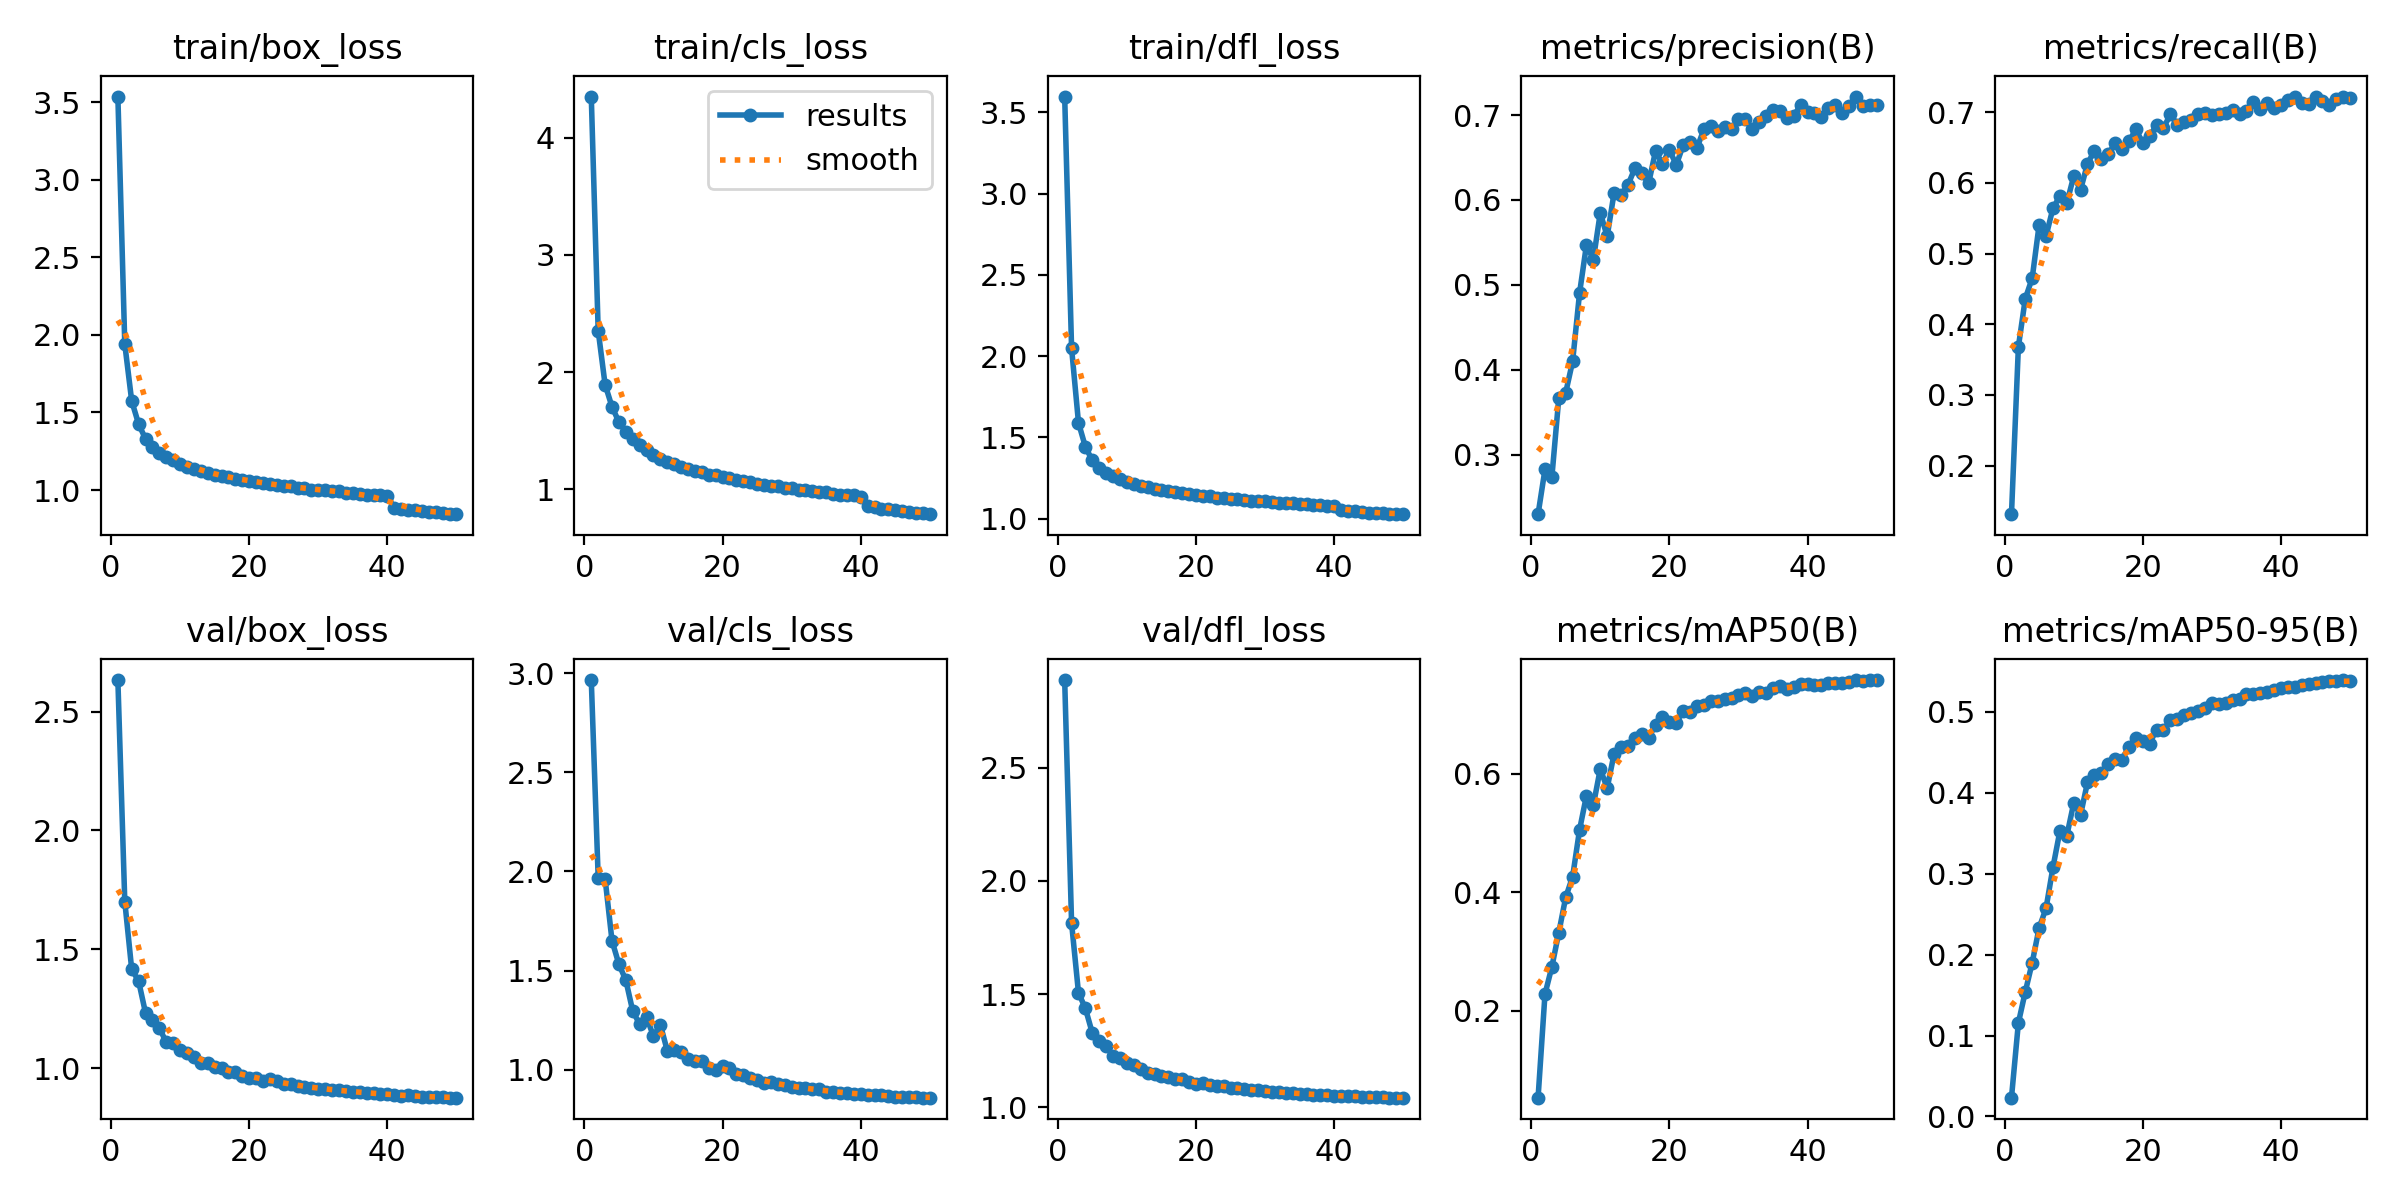


🧩 [2] 혼동 행렬 (Confusion Matrix)
   - 대각선이 진할수록 해당 클래스를 잘 맞춘 것입니다.


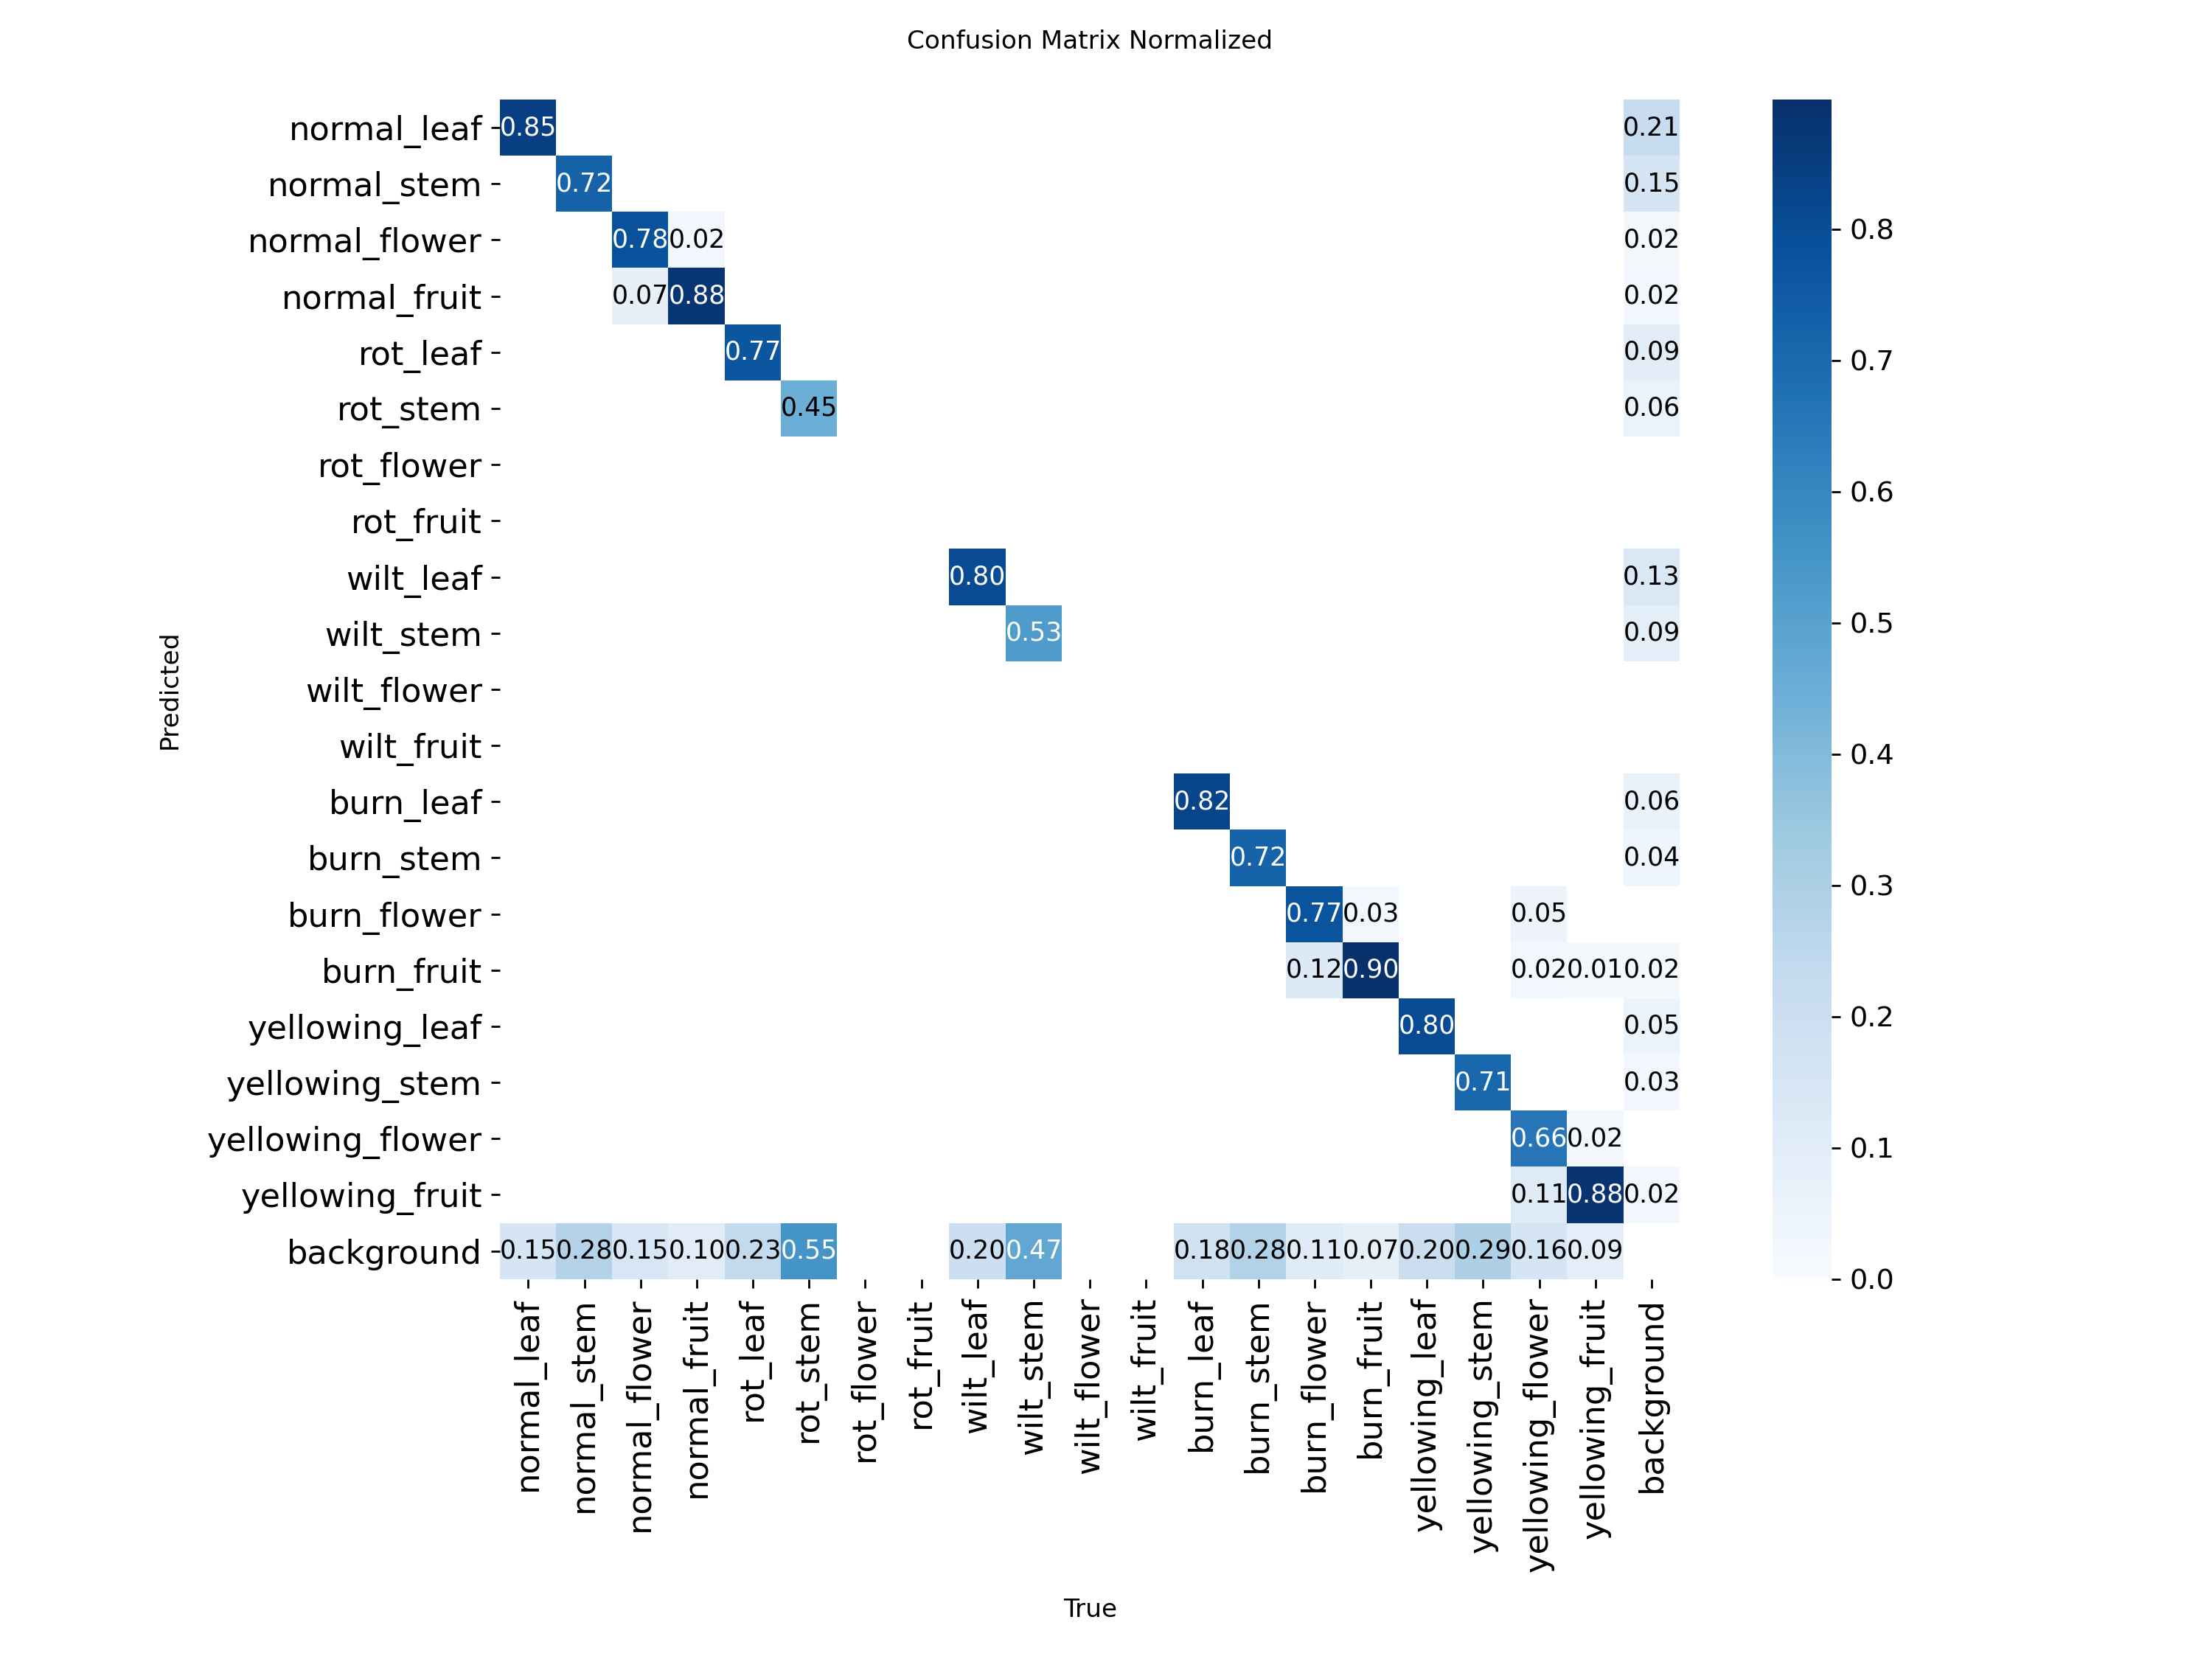

In [ ]:
import os
import pandas as pd
from IPython.display import Image, display

# 설정된 결과 경로 (학습 때 정한 project + name)
result_dir = '/content/drive/MyDrive/KTD_Result/KTD_Final_Train'

# 1. 학습 곡선 (Loss & mAP)
results_img = os.path.join(result_dir, 'results.png')
if os.path.exists(results_img):
    print("📈 [1] 학습 곡선 (Learning Curves)")
    print("   - 왼쪽 그래프(Loss)는 내려가야 하고, 오른쪽 그래프(mAP)는 올라가야 정상입니다.")
    display(Image(filename=results_img, width=800))
else:
    print("❌ results.png 파일이 없습니다. 학습이 아직 안 끝났거나 에러가 났을 수 있습니다.")

# 2. 혼동 행렬 (Confusion Matrix)
conf_matrix = os.path.join(result_dir, 'confusion_matrix_normalized.png')
if not os.path.exists(conf_matrix):
    conf_matrix = os.path.join(result_dir, 'confusion_matrix.png')

if os.path.exists(conf_matrix):
    print("\n🧩 [2] 혼동 행렬 (Confusion Matrix)")
    print("   - 대각선이 진할수록 해당 클래스를 잘 맞춘 것입니다.")
    display(Image(filename=conf_matrix, width=600))


🍓 [3] 실제 탐지 예시 (3장 발견)
   👉 파일명: val_batch0_pred.jpg


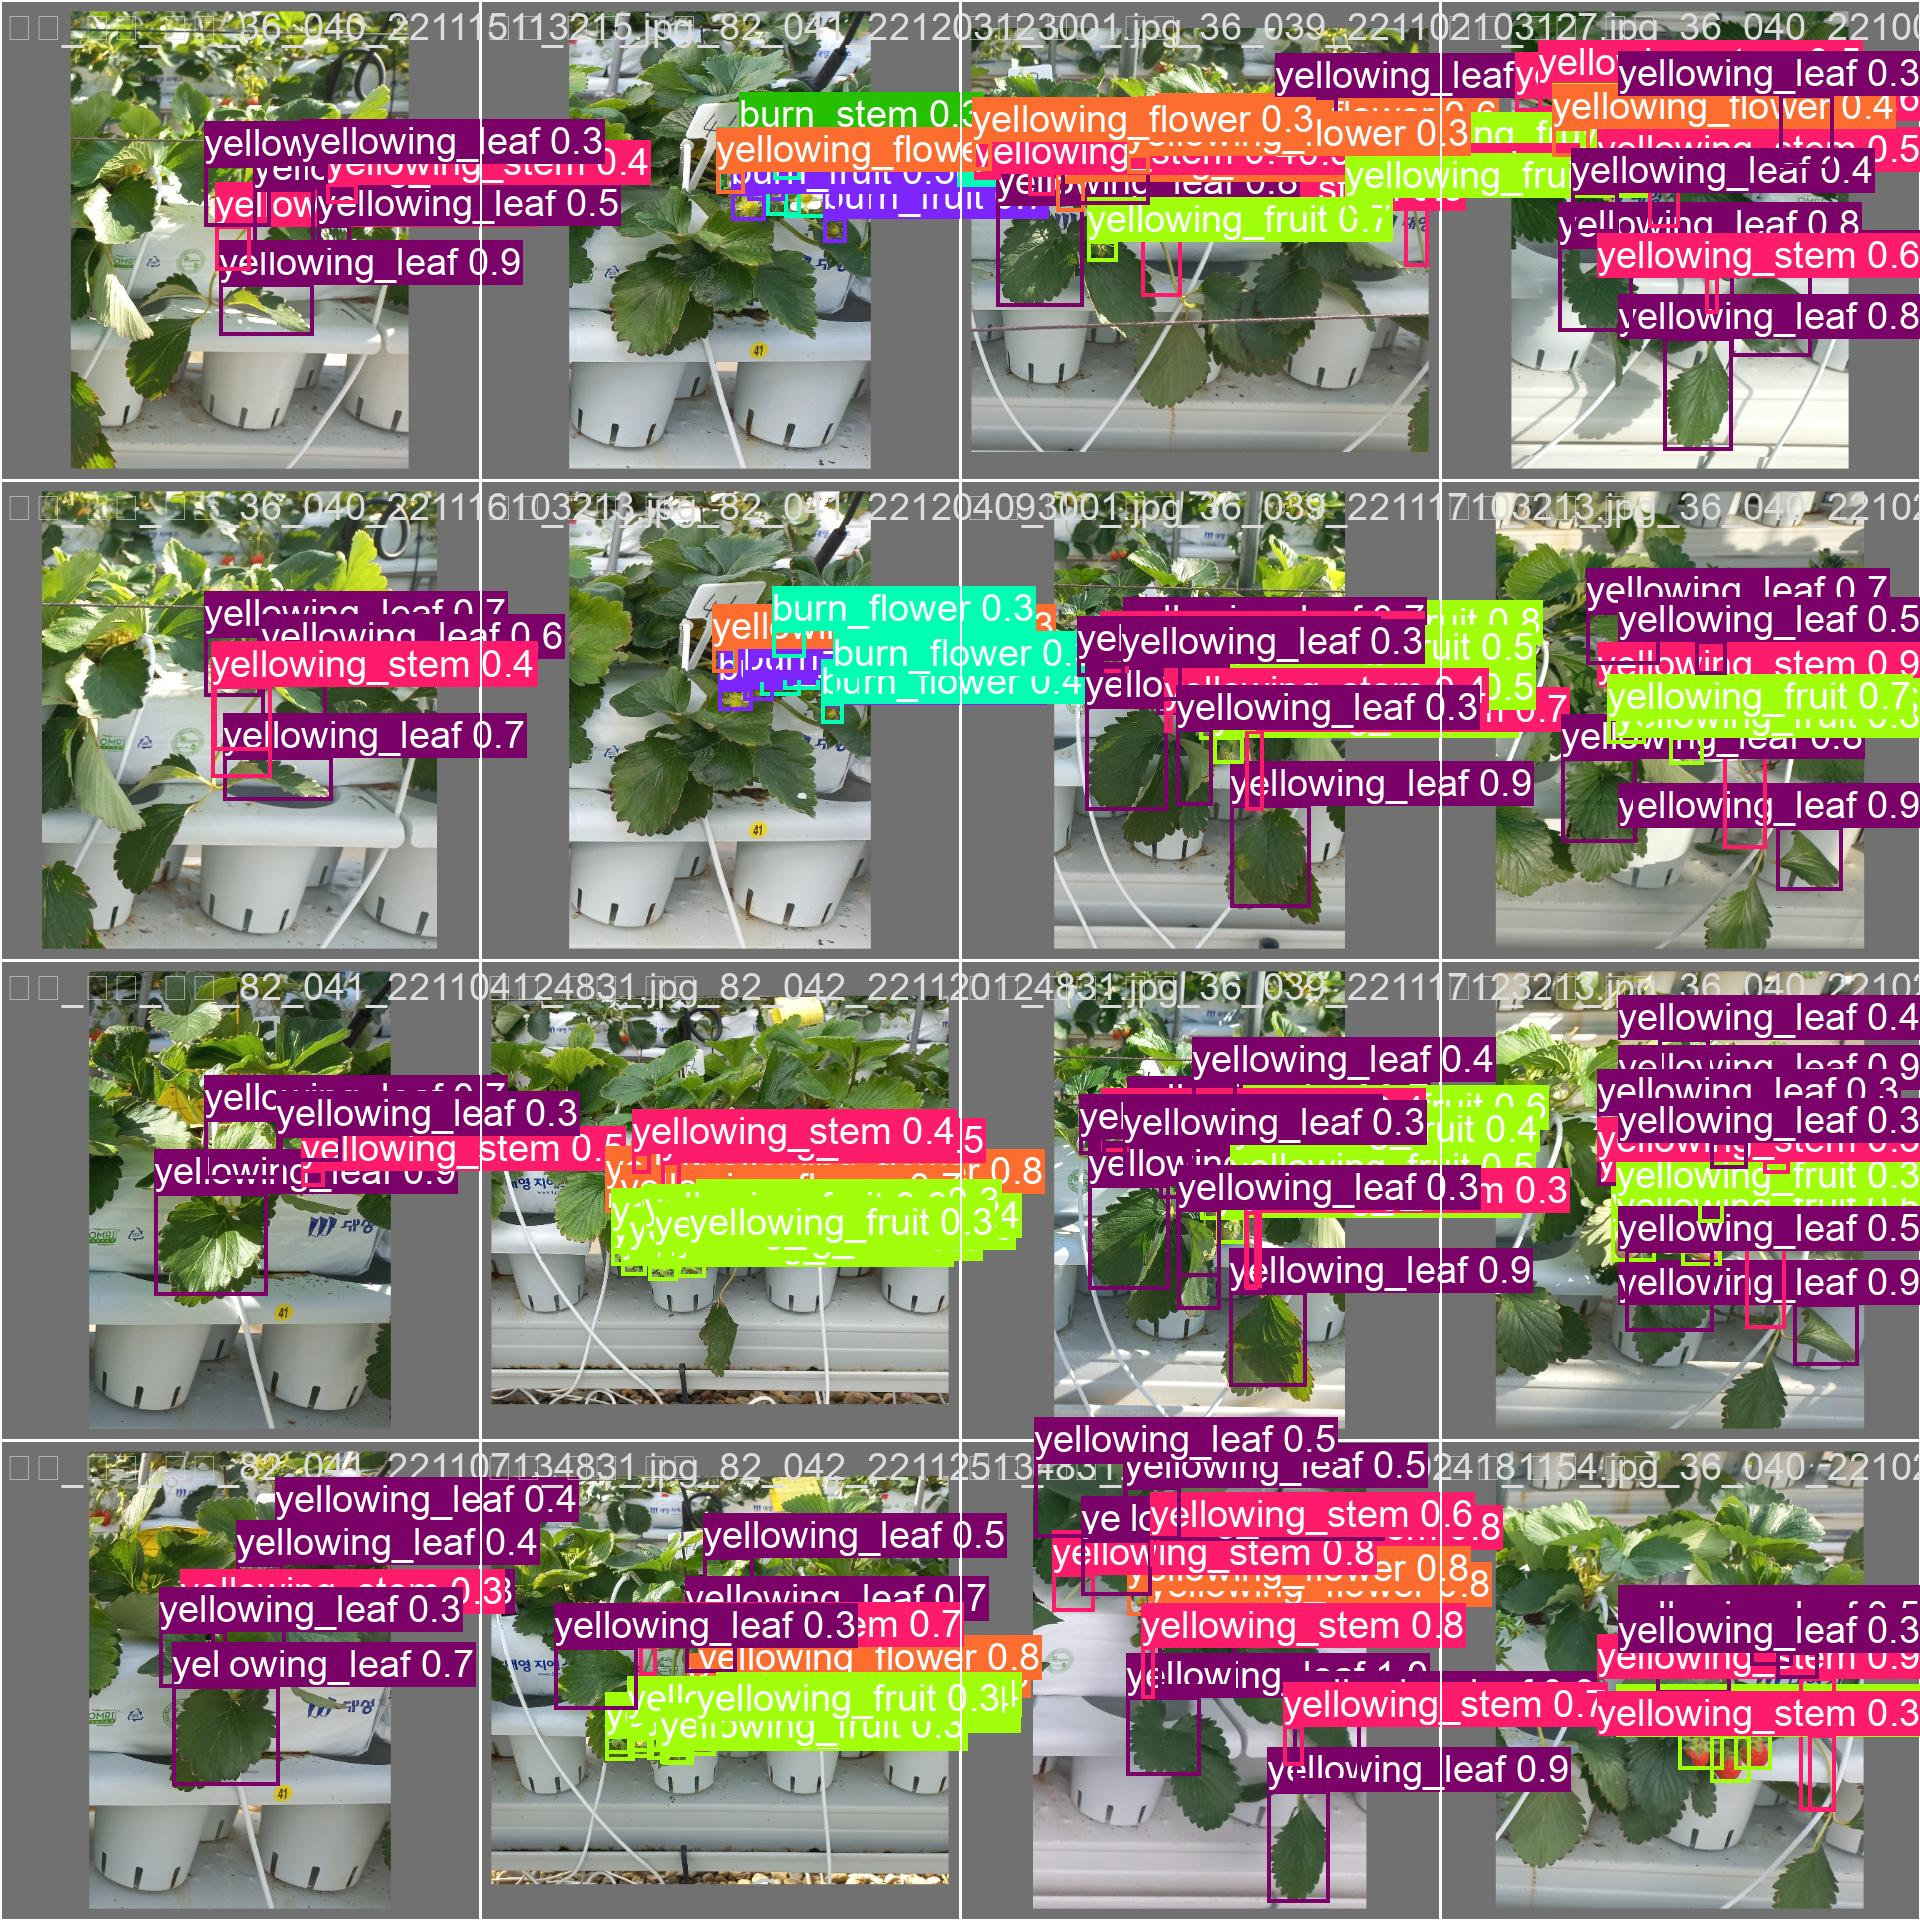

   👉 파일명: val_batch1_pred.jpg


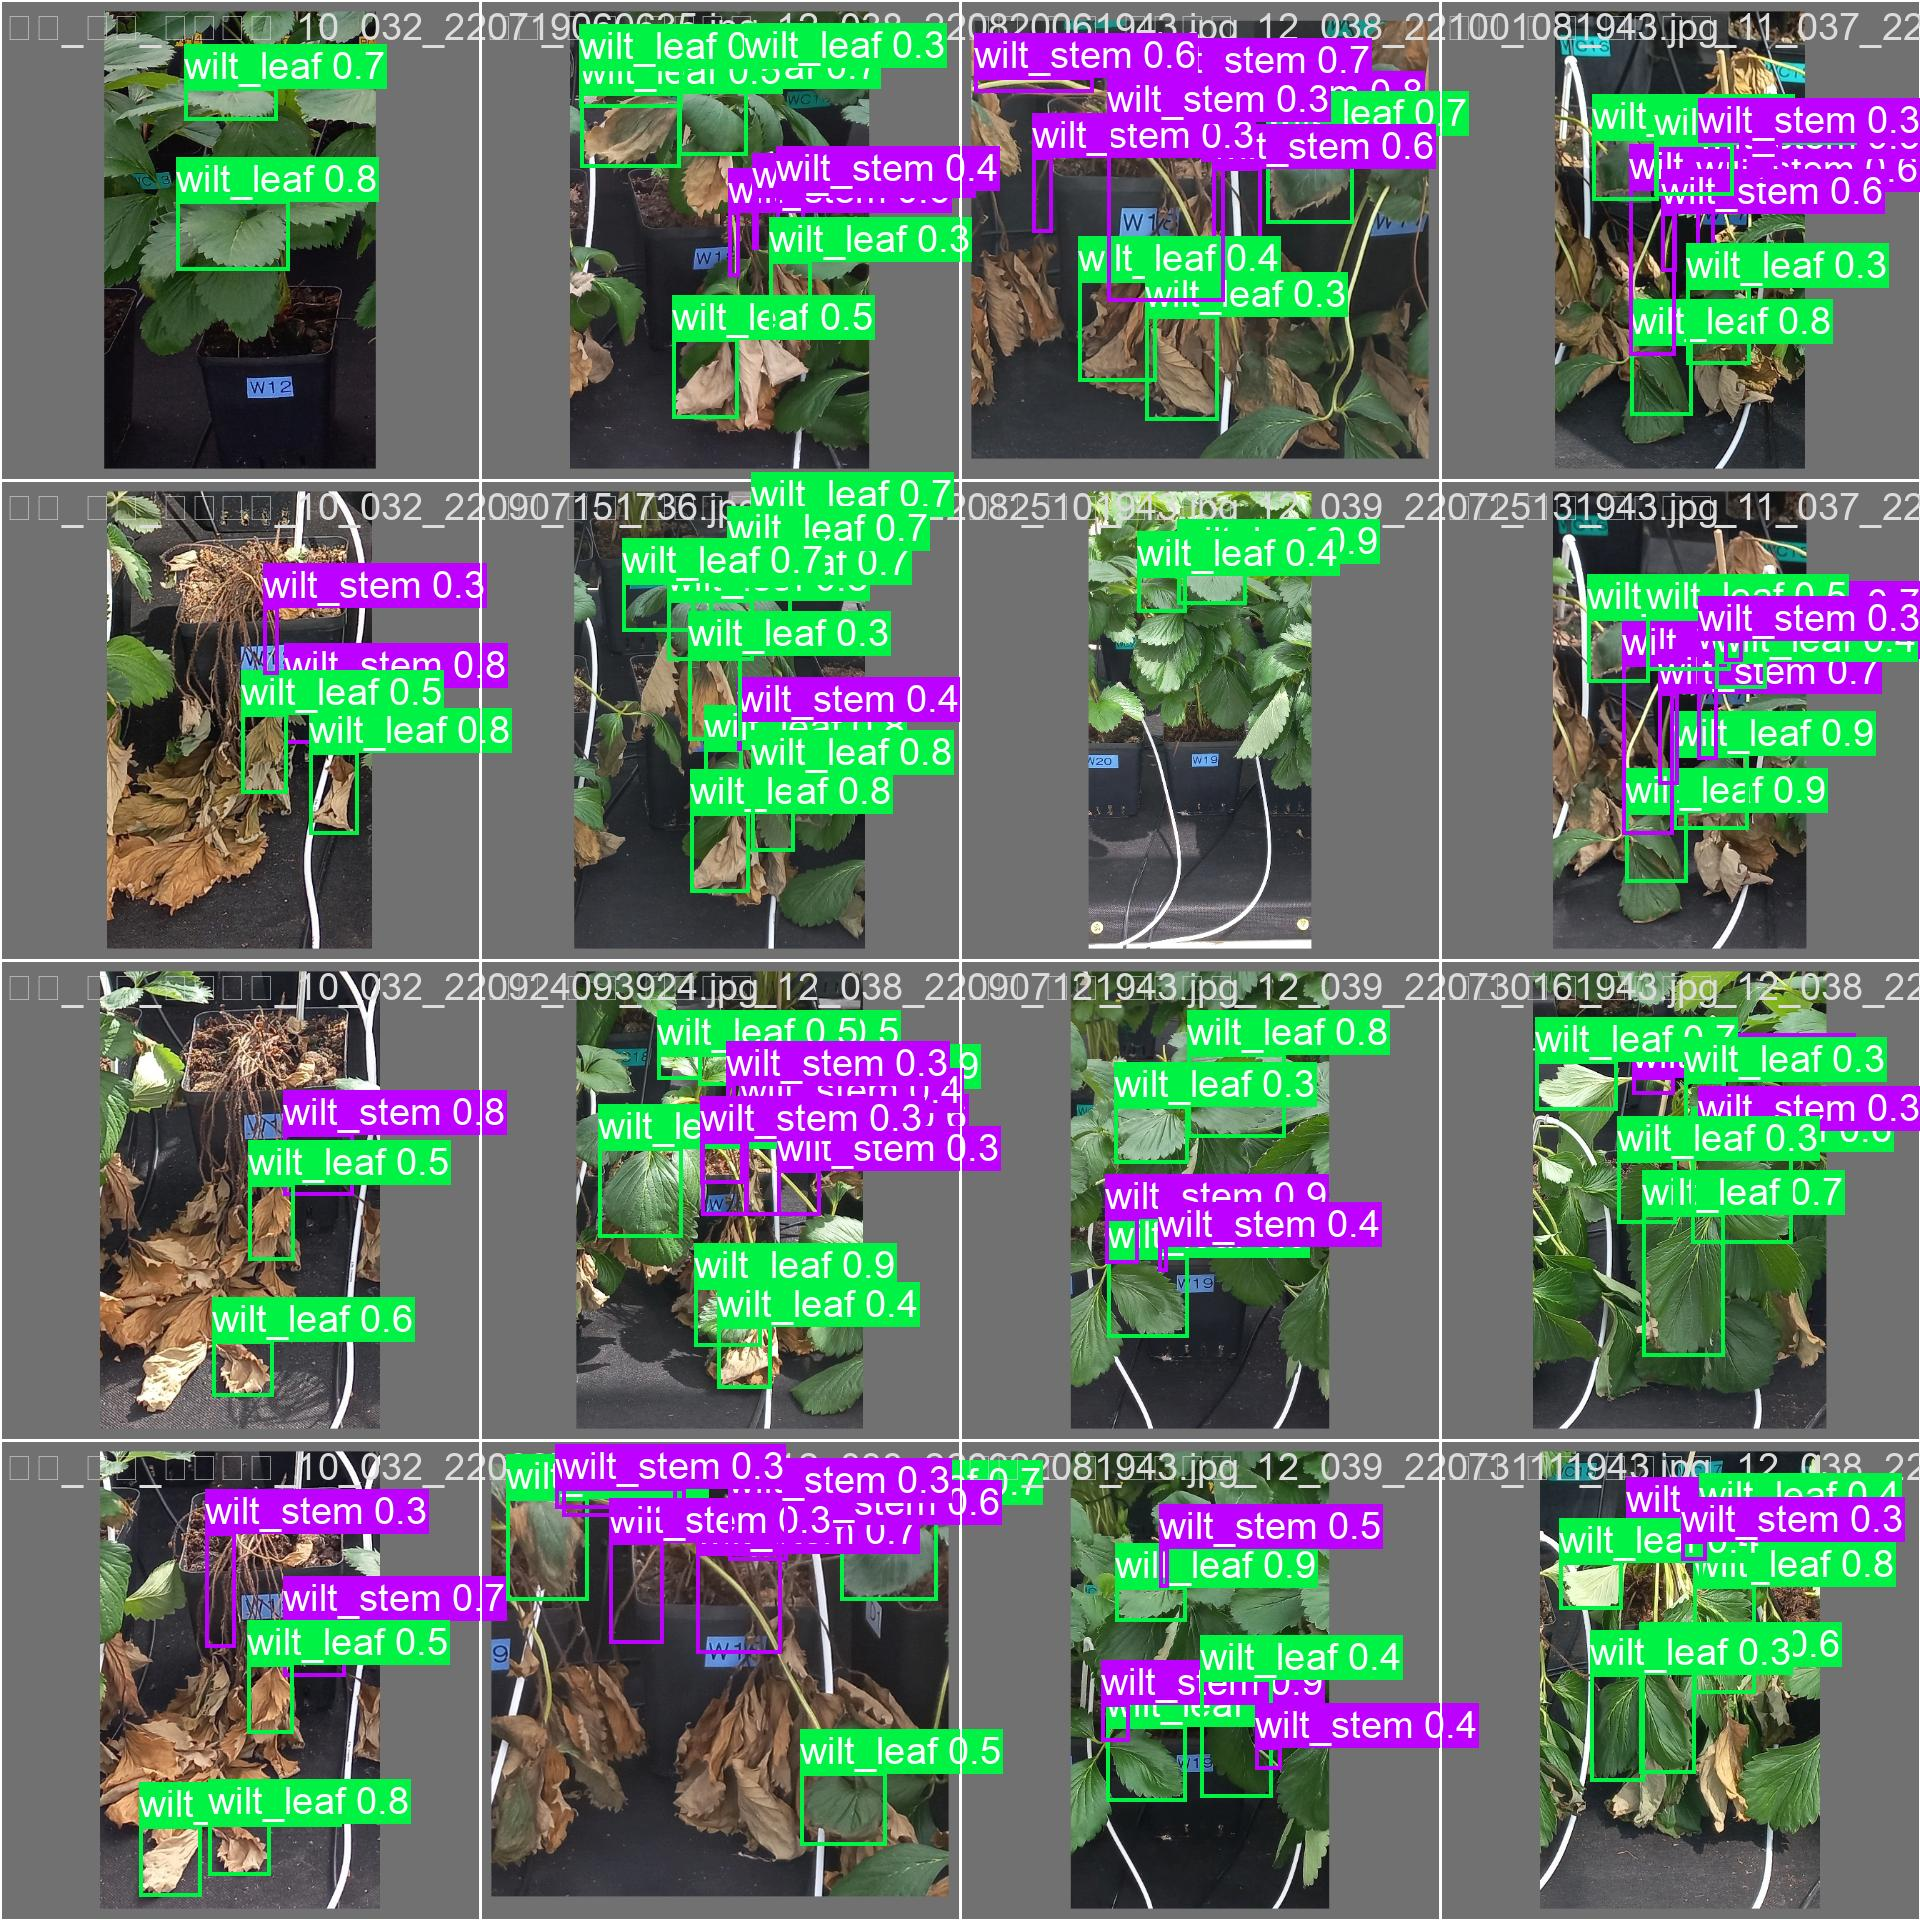

   👉 파일명: val_batch2_pred.jpg


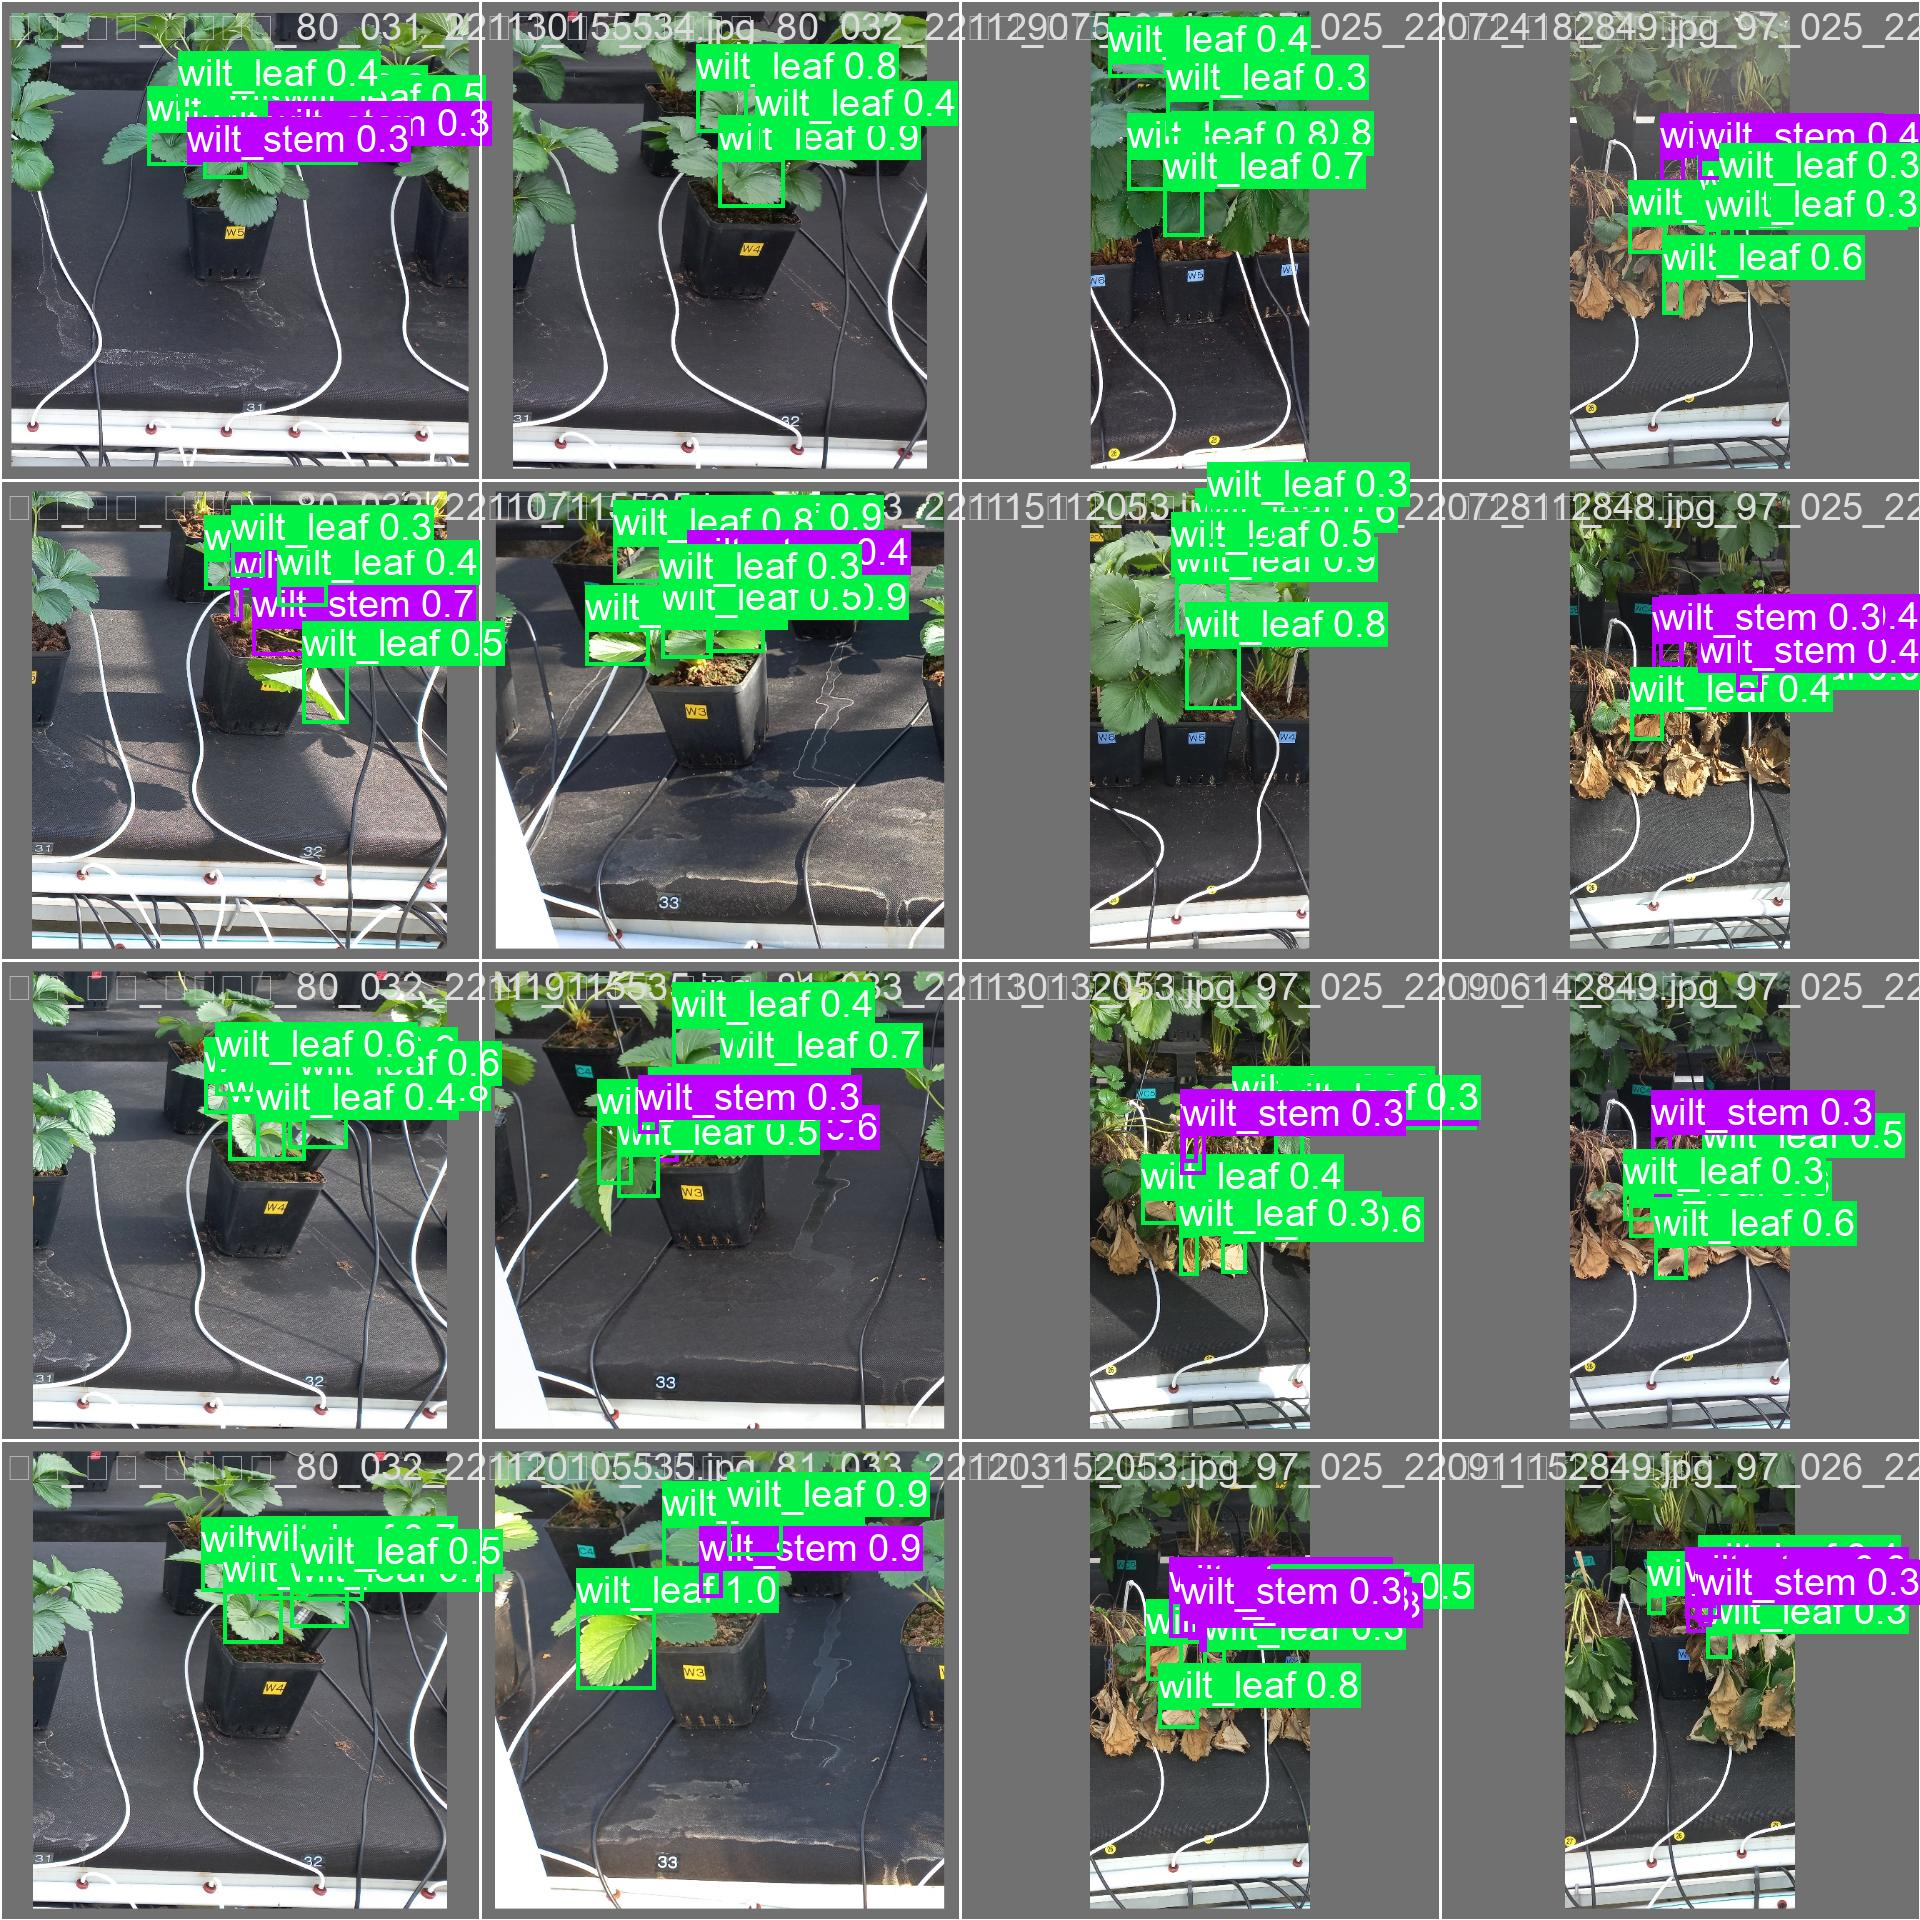

In [ ]:
import glob

# val_batch*_pred.jpg 파일들을 찾아서 보여줍니다.
pred_images = glob.glob(os.path.join(result_dir, 'val_batch*_pred.jpg'))
pred_images.sort()

if len(pred_images) > 0:
    print(f"\n🍓 [3] 실제 탐지 예시 ({len(pred_images)}장 발견)")
    for img_path in pred_images[:3]: # 너무 많으니 3장만 출력
        print(f"   👉 파일명: {os.path.basename(img_path)}")
        display(Image(filename=img_path, width=800))
else:
    print("❌ 예측 예시 이미지가 없습니다.")


🎲 랜덤 테스트 이미지 선택: 딸기_설향_잎끝마름_27_016_221026120521.jpg

image 1/1 /content/datasets/strawberry/images/test/딸기_설향_잎끝마름_27_016_221026120521.jpg: 640x640 3 burn_leafs, 6 burn_fruits, 9.5ms
Speed: 1.7ms preprocess, 9.5ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46392 (\N{HANGUL SYLLABLE DDAL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49444 (\N{HANGUL SYLLABLE SEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54693 (\N{HANGUL SYLLABLE HYANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51086 (\N{HANGUL SYLLABLE IP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

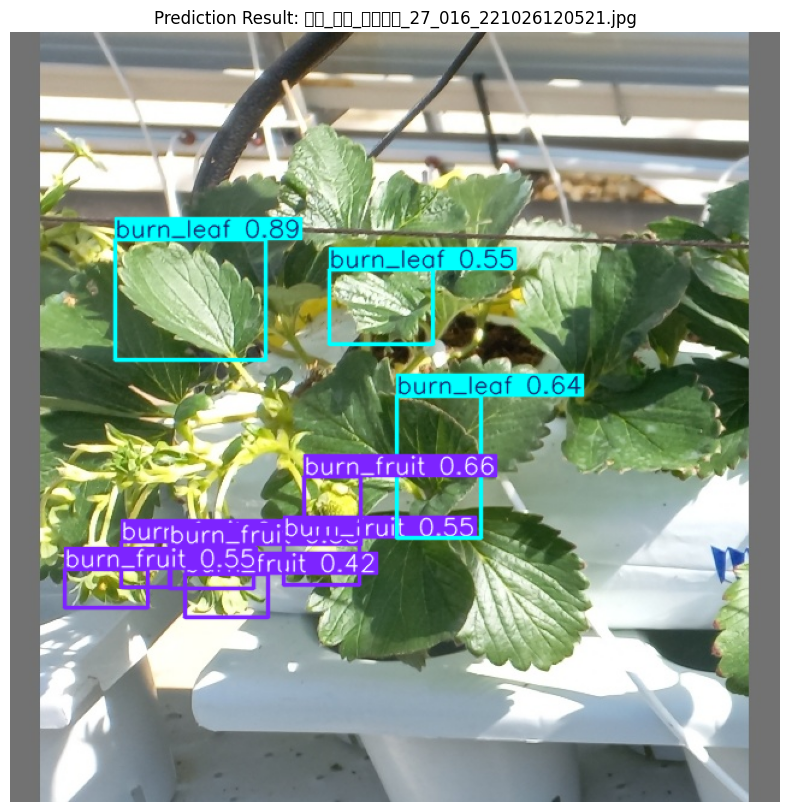

In [ ]:
import random
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# 1. 학습된 최적 모델 로드 (Monkey Patching이 되어 있어야 함)
best_model_path = os.path.join(result_dir, 'weights', 'best.pt')

# 메모리에 TripletAttention이 주입된 상태여야 로드 가능
try:
    best_model = YOLO(best_model_path)

    # 2. Test 이미지 폴더에서 랜덤 한 장 선택
    test_images_dir = '/content/datasets/strawberry/images/test' # 데이터셋 경로 확인
    test_imgs = glob.glob(os.path.join(test_images_dir, '*.jpg')) + \
                glob.glob(os.path.join(test_images_dir, '*.png'))

    if len(test_imgs) > 0:
        random_img = random.choice(test_imgs)
        print(f"\n🎲 랜덤 테스트 이미지 선택: {os.path.basename(random_img)}")

        # 3. 추론 실행
        results = best_model.predict(random_img, conf=0.25) # conf: 확신도가 0.25 이상인 것만 표시

        # 4. 결과 시각화
        for result in results:
            res_plotted = result.plot() # 박스 그려진 이미지 생성

            # Matplotlib으로 출력 (BGR -> RGB 변환 필요)
            plt.figure(figsize=(10, 10))
            plt.imshow(cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB))
            plt.axis('off')
            plt.title(f"Prediction Result: {os.path.basename(random_img)}")
            plt.show()
    else:
        print("❌ 테스트 이미지를 찾을 수 없습니다.")

except Exception as e:
    print(f"❌ 모델 로드 중 오류 발생: {e}")
    print("   (팁: TripletAttention 클래스 정의 코드를 다시 실행해주세요.)")

In [ ]:
# @title
import torch
import torch.nn as nn
import ultralytics.nn.tasks as tasks
from ultralytics import YOLO

# ==============================================================================
# 1. Triplet Attention 모듈 직접 정의 (메모리에 로드)
# ==============================================================================
class BasicConv(nn.Module):
    def __init__(self, in_planes, out_planes, kernel_size, stride=1, padding=0, dilation=1, groups=1, relu=True, bn=True, bias=False):
        super(BasicConv, self).__init__()
        self.out_channels = out_planes
        self.conv = nn.Conv2d(in_planes, out_planes, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups, bias=bias)
        self.bn = nn.BatchNorm2d(out_planes, eps=1e-5, momentum=0.01, affine=True) if bn else None
        self.relu = nn.ReLU() if relu else None

    def forward(self, x):
        x = self.conv(x)
        if self.bn is not None:
            x = self.bn(x)
        if self.relu is not None:
            x = self.relu(x)
        return x

class TripletAttention(nn.Module):
    def __init__(self, no_spatial=False):
        super(TripletAttention, self).__init__()
        # 논문 구현: 7x7 Conv + BN (Activation은 뒤에서 Sigmoid 사용)
        self.cw = BasicConv(2, 1, 7, padding=3, relu=False)
        self.hc = BasicConv(2, 1, 7, padding=3, relu=False)
        self.no_spatial = no_spatial
        if not no_spatial:
            self.hw = BasicConv(2, 1, 7, padding=3, relu=False)

    def forward(self, x):
        # Channel-Width branch
        x_perm1 = x.permute(0, 2, 1, 3).contiguous()
        x_out1 = self.cw(torch.cat((torch.max(x_perm1, 1)[0].unsqueeze(1), torch.mean(x_perm1, 1).unsqueeze(1)), dim=1))
        x_out1 = x_out1.sigmoid()
        x_out1 = x_out1.permute(0, 2, 1, 3).contiguous()

        # Height-Channel branch
        x_perm2 = x.permute(0, 3, 2, 1).contiguous()
        x_out2 = self.hc(torch.cat((torch.max(x_perm2, 1)[0].unsqueeze(1), torch.mean(x_perm2, 1).unsqueeze(1)), dim=1))
        x_out2 = x_out2.sigmoid()
        x_out2 = x_out2.permute(0, 3, 2, 1).contiguous()

        # Height-Width branch (Spatial)
        if not self.no_spatial:
            x_out = self.hw(torch.cat((torch.max(x, 1)[0].unsqueeze(1), torch.mean(x, 1).unsqueeze(1)), dim=1))
            x_out = x_out.sigmoid()
            return 1/3 * (x * x_out + x * x_out1 + x * x_out2)
        else:
            return 1/2 * (x * x_out1 + x * x_out2)

# ==============================================================================
# 2. Ultralytics 라이브러리에 강제 주입 (Monkey Patching)
# ==============================================================================
# tasks.py가 모델을 파싱할 때 이 클래스를 찾을 수 있도록 globals에 넣어줍니다.
tasks.TripletAttention = TripletAttention
# 혹시 모르니 모듈 자체에도 속성으로 등록
if not hasattr(tasks, 'TripletAttention'):
    setattr(tasks, 'TripletAttention', TripletAttention)

print("✅ TripletAttention 모듈이 메모리에 성공적으로 주입되었습니다!")

# ==============================================================================
# 3. 모델 학습 시작
# ==============================================================================
# 경로 설정 (사용자 환경 기준)
ktd_yaml_path = '/content/ktd_yolov8_strawberry.yaml'
data_yaml_path = '/content/datasets/strawberry/strawberry_ktd_final.yaml'

print("\n🚀 KTD-YOLOv8 모델 빌드 및 학습 시작...")

# 이제 주입된 클래스를 인식할 수 있습니다.
model = YOLO(ktd_yaml_path).load('yolov8s.pt')

model.train(
    data=data_yaml_path,
    epochs=10,
    imgsz=640,
    batch=16,
    project='/content/drive/MyDrive/KTD_Result',
    name='KTD_Final_Train',
    exist_ok=True
)